# 4 Morphological Operations

**과제 목표:** 원본 얼룩말 사진에 팽창(Dilation), 침식(Erosion), 열림(Opening), 닫힘(Closing)을 구현·적용하고 결과를 비교한다.

교안의 정의에 맞춰 **하나의 5×5 정사각형 구조 요소**를 네 연산 모두에 사용한다.

In [12]:
from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw

## 1. 원본 이미지 / Original Image

직접 업로드한 `zebra1.jpeg`의 어두운 줄무늬는 폭이 다양하고 사이에 가느다란 밝은 틈이 있어 형태학적 연산의 효과를 관찰하기 좋다. 아래 셀은 **과제의 원본 사진**을 표시한다.
</br>

The uploaded `zebra1.jpeg` is well suited for demonstrating morphological operations because its dark stripes vary in width and are separated by narrow light gaps. The cell below displays the **original image used for this assignment**.

Original: 678 × 452 pixels


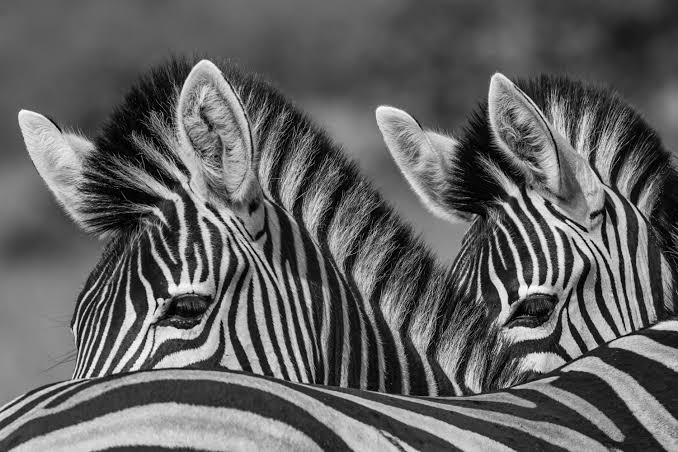

In [13]:
source_path = Path("zebra1.jpeg")
original = Image.open(source_path).convert("RGB")
print(f"Original: {original.width} × {original.height} pixels")
display(original)

## 2. 이진화와 구조 요소 / Binaization and Sturcturing Element

원본 이미지를 회색조로 변환한 뒤 Otsu 임계값으로 이진화한다. 임계값 이상의 밝은 픽셀은 흰색, 임계값보다 어두운 픽셀은 검은색으로 표시한다. 따라서 얼룩말의 어두운 줄무늬는 검은색으로 남고, 흰색으로 표시된 밝은 영역을 전경으로 처리한다.
</br>

The original image is converted to grayscale and then binarized using Otsu's threshold. Pixels at or above the threshold are displayed as white, while darker pixels are displayed as black. The zebra's dark stripes therefore remain black, and the morphological operations treat the brighter regions as foreground.

Otsu threshold: 113; black = dark zebra stripes


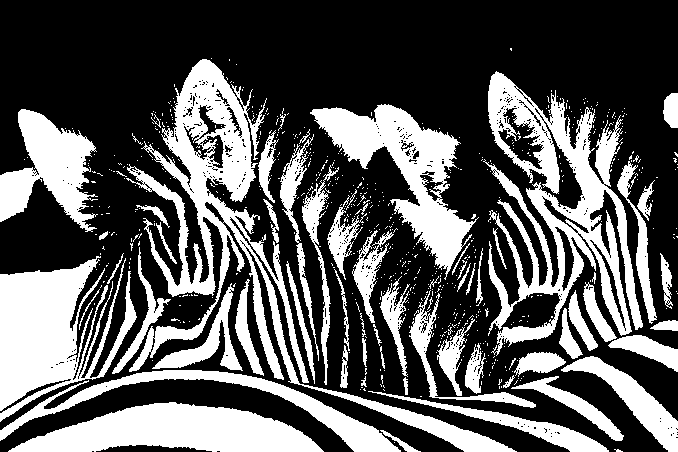

In [18]:
# 어두운 줄무늬를 검은색, 나머지를 흰색으로 표현합니다.
gray = np.asarray(original.convert("L"), dtype=np.uint8)
hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
prob = hist / hist.sum()
omega = np.cumsum(prob)
mu = np.cumsum(prob * np.arange(256))
between_class_variance = (mu[-1] * omega - mu) ** 2 / np.maximum(omega * (1 - omega), 1e-12)
threshold = int(np.argmax(between_class_variance[:-1]))  # Otsu threshold
binary = gray >= threshold

def as_image(mask):
    return Image.fromarray(mask.astype(np.uint8) * 255)

print(f"Otsu threshold: {threshold}; black = dark zebra stripes")
display(as_image(binary))


## 3. 네 연산 구현 / 4 Morphological Operations

팽창은 구조 요소가 전경에 **한 번이라도 닿으면** 해당 화소를 전경으로 만든다. 침식은 구조 요소의 **모든 위치가 전경 안에 들어가야** 해당 화소를 유지한다. 교안에 따라 열림은 **침식 → 팽창**, 닫힘은 **팽창 → 침식** 순서다.
</br>

In dilation, an output pixel becomes foreground if at least one active position of the structuring element overlaps a foreground pixel. In erosion, an output pixel remains foreground only if every active position of the structuring element overlaps the foreground. Opening applies erosion followed by dilation, while closing applies dilation followed by erosion.

In [15]:
# 교안과 같이 모든 연산에 동일한 5×5 정사각형 구조 요소(SE)를 사용합니다.
SE = np.ones((5, 5), dtype=bool)

def _morph(mask, se, operation):
    mask = np.asarray(mask, dtype=bool)
    se = np.asarray(se, dtype=bool)
    assert mask.ndim == 2 and se.ndim == 2
    assert se.shape[0] % 2 == 1 and se.shape[1] % 2 == 1 and se.any()

    height, width = mask.shape
    pad_y, pad_x = se.shape[0] // 2, se.shape[1] // 2
    # 침식의 영상 바깥쪽은 True(중립값), 팽창은 False(중립값)로 둡니다.
    is_erosion = operation == "erosion"
    padded = np.pad(mask, ((pad_y, pad_y), (pad_x, pad_x)),
                    mode="constant", constant_values=is_erosion)
    result = np.ones_like(mask) if is_erosion else np.zeros_like(mask)

    for y, x in np.argwhere(se):
        region = padded[y:y + height, x:x + width]
        if is_erosion:
            result &= region  # SE의 모든 위치가 전경이어야 유지
        else:
            result |= region  # SE의 한 위치라도 전경이면 확장
    return result

def dilation(mask, se):
    return _morph(mask, se, "dilation")

def erosion(mask, se):
    return _morph(mask, se, "erosion")

def opening(mask, se):
    return dilation(erosion(mask, se), se)

def closing(mask, se):
    return erosion(dilation(mask, se), se)


## 4. 네 가지 형태학적 연산 적용 / Applying the Four Operations

동일한 5×5 정사각형 구조 요소(`SE`)를 사용하여 입력 영상에 Dilation, Erosion, Opening, Closing을 적용한다. 각 결과는 `results` 딕셔너리에 저장한다.
</br>

Dilation, erosion, opening, and closing are applied to the input image using the same 5×5 square structuring element (`SE`). Each output is stored in the `results` dictionary.

In [16]:
results = {
    "Dilation": dilation(binary, SE),
    "Erosion": erosion(binary, SE),
    "Opening": opening(binary, SE),
    "Closing": closing(binary, SE),
}

## 5. 원본과 결과 이미지 / Results

**원본 전체 사진 + 이진 입력 + 네 결과**를 한 장에서 같은 크기로 비교한다. 각 이미지는 `morphology_outputs/`에 개별 PNG로 저장된다.
</br>

The full original photo, the binary input, and the four processed results are shown together at the same size in one comparison image. Each is also saved as a separate PNG file in `morphology_outputs/`.

Full-image comparison (all panels use the same source and scale):


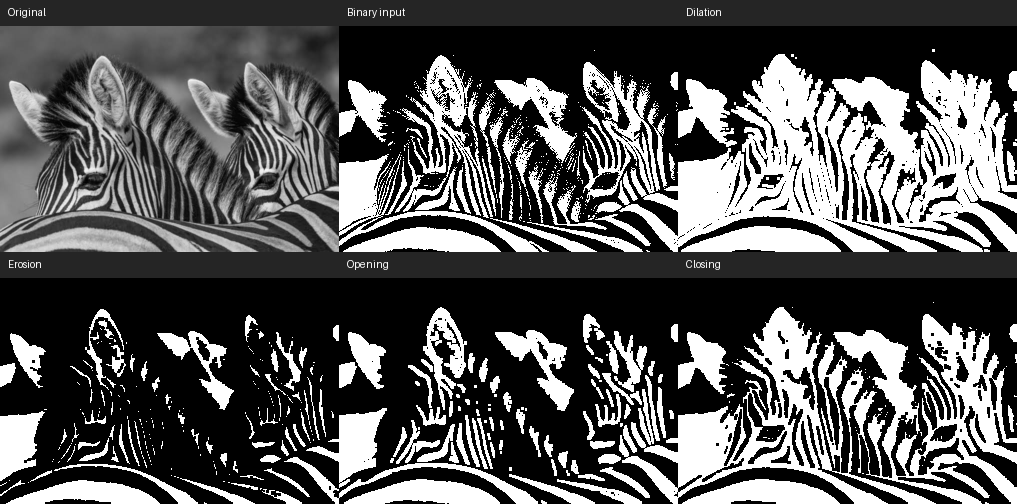

Saved 7 PNG files in morphology_outputs/


In [17]:
# 원본, 이진 입력, 네 결과를 개별 PNG 파일로 저장합니다.
out_dir = Path("morphology_outputs")
out_dir.mkdir(exist_ok=True)
original.save(out_dir / "01_original.png")
as_image(binary).save(out_dir / "02_binary_input.png")
for index, (name, img) in enumerate(results.items(), start=3):
    as_image(img).save(out_dir / f"{index:02d}_{name.lower()}.png")

def comparison_panel(items, columns=3, tile_width=339, title_height=26):
    rows = (len(items) + columns - 1) // columns
    tile_height = round(tile_width * original.height / original.width)
    panel = Image.new("RGB", (columns * tile_width, rows * (tile_height + title_height)), "#e8e8e8")
    draw = ImageDraw.Draw(panel)
    for index, (label, img) in enumerate(items):
        col, row = index % columns, index // columns
        x, y = col * tile_width, row * (tile_height + title_height)
        draw.rectangle((x, y, x + tile_width - 1, y + title_height - 1), fill="#252525")
        draw.text((x + 8, y + 6), label, fill="white")
        pil_img = img if isinstance(img, Image.Image) else as_image(img)
        resample = Image.Resampling.BILINEAR if label == "Original" else Image.Resampling.NEAREST
        panel.paste(pil_img.convert("RGB").resize((tile_width, tile_height), resample), (x, y + title_height))
    return panel

panel = comparison_panel([
    ("Original", original), ("Binary input", binary),
    ("Dilation", results["Dilation"]), ("Erosion", results["Erosion"]),
    ("Opening", results["Opening"]), ("Closing", results["Closing"]),
])
panel.save(out_dir / "07_comparison.png")
print("Full-image comparison (all panels use the same source and scale):")
display(panel)

print(f"Saved 7 PNG files in {out_dir}/")

## 6. 관찰 및 비교 / Observation and Comparison

| 연산 | 교안의 순서/원리 | 전체 사진에서 보이는 변화 |
|---|---|---|
| Dilation | 구조 요소가 전경에 닿으면 확장 | 밝은 털 영역이 넓어지고 검은 줄무늬는 가늘어진다. |
| Erosion | 구조 요소가 전경에 완전히 들어가야 유지 | 밝은 영역이 줄어들고 검은 줄무늬는 굵어진다. |
| Opening | 침식 후 팽창 | 가느다란 밝은 부분이 줄어들고 넓은 밝은 영역은 비교적 유지된다. |
| Closing | 팽창 후 침식 | 넓은 밝은 영역의 형태는 비교적 유지되며 좁은 검은 간격이 줄어든다. |

Dilation과 Erosion은 전경의 크기를 바꾸고, 열림과 닫힘은 큰 형태를 비교적 유지한다.
</br>

| Operation | Order / principle from the lecture | Changes observed in the full image |
|---|---|---|
| Dilation | Expands the white foreground wherever the structuring element touches it | Bright fur regions expand, and the dark stripes become thinner. |
| Erosion | Keeps a foreground pixel only when the structuring element fits entirely within the white foreground | Bright regions shrink, and the dark stripes become thicker. Thin bright details may disappear. |
| Opening | Erosion followed by dilation | Thin bright details are reduced, while broader bright regions are largely preserved. |
| Closing | Dilation followed by erosion | Broader bright regions largely retain their shape, while narrow dark gaps become smaller. |

Dilation and erosion directly change the size of the white foreground. Opening and closing largely preserve bigger shapes while changing fine details.